**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 6
MEDIUM_SIZE = 8
BIGGER_SIZE = 10

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

## marker genes for neuronal/non-neuronal cells

In [5]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte",
        "OPCs", # oligodendrocyte progenitor cells 
        "Microglia","interneuron","astrocytes","neuroblast"
    ],

    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

In [254]:
marker_genes = {
    "OPCs":['Pdgfra','Olig2'], # oligodendrocyte progenitor cells
    "interneuron":[
        # "Resp18",
        # 'Lhx6',
        'Zic1'
    ],
    "Endothelial": ["Cldn5","Ptprb"],
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":["Aqp4",'Slc1a3','Gja1'],
    "neuroblast":["Top2a"],
    # "neuron main markers":[
    #     # 'Snap25',
    #     'Zic2',#"Gria2", "Penk",'Dck','Nrxn1',"Nfasc","Kctd13",
    #     "Sox11" #"Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
    #                       ],
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Gria1",
        # "Gria2",
        # "Grin1",
        # "Slc6a13",
        # "Slc7a11",
        # "Slc17a7",
        # "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    # "D2 MSN":[ # (Ppp1r1b+ medial spiny neuron)
    #     "Penk",
    #     # "Drd2",
    #     "Adora2a"
    # ],
    # "D1H":[
        # "Nxph4",
    #     # "Tac2"
    # ],
    # "ICj":[
    #     # "Crtac1",
    #     "Rreb1"],
    # "patch marker":["Sema5b"],
    # "ventral striatum marker":["Crym"],
    # "medial Shell":[
    #     "Stard5",
    #     "Stra6"]
}

In [255]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

## `scvi` denoised

In [208]:
results_file = 'celltyping/adata-denoised-clustered.h5ad.gz'

adata = sc.read_h5ad(results_file)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [209]:
del adata.raw

In [210]:
adata.var_names_make_unique()

### Label Neuron

In [211]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels', '_scvi_local_l_mean', '_scvi_local_l_var', 'leiden_scVI', 'Snap25 label', 'TdT label', 'Sox11 label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: '_scvi', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_scVI_colors', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categoricals'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [212]:
leiden_list = []
for l in adata.obs.leiden_scVI:
    if int(l) in [0,1,2,6,7,12,13,14,15,18,19,20,21]: leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [213]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [214]:
adata_neuron

AnnData object with n_obs × n_vars = 13006 × 10013
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels', '_scvi_local_l_mean', '_scvi_local_l_var', 'leiden_scVI', 'Snap25 label', 'TdT label', 'Sox11 label', 'label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: '_scvi', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_scVI_colors', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categoricals'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [215]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [216]:
adata_neuron

AnnData object with n_obs × n_vars = 13006 × 10013
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels', '_scvi_local_l_mean', '_scvi_local_l_var', 'leiden_scVI', 'Snap25 label', 'TdT label', 'Sox11 label', 'label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: '_scvi', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_scVI_colors', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categoricals'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [217]:
sc.tl.pca(adata_neuron)

In [236]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_neuron, use_rep="X_scVI")
sc.tl.umap(adata_neuron, min_dist=1)

In [237]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.3)

In [238]:
sc.pl.umap(
    adata_neuron,
    color=['Snap25','Sox11','Grin3a','Gt(ROSA)26Sor','Gria1','group',
           "leiden_scVI",'leiden_neuron'],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    # legend_loc='on data',
    add_outline=0.1
)

In [221]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

categories: 0, 1, 2, etc.
var_group_labels: GABAergic, glutamatergic, D1 MSN


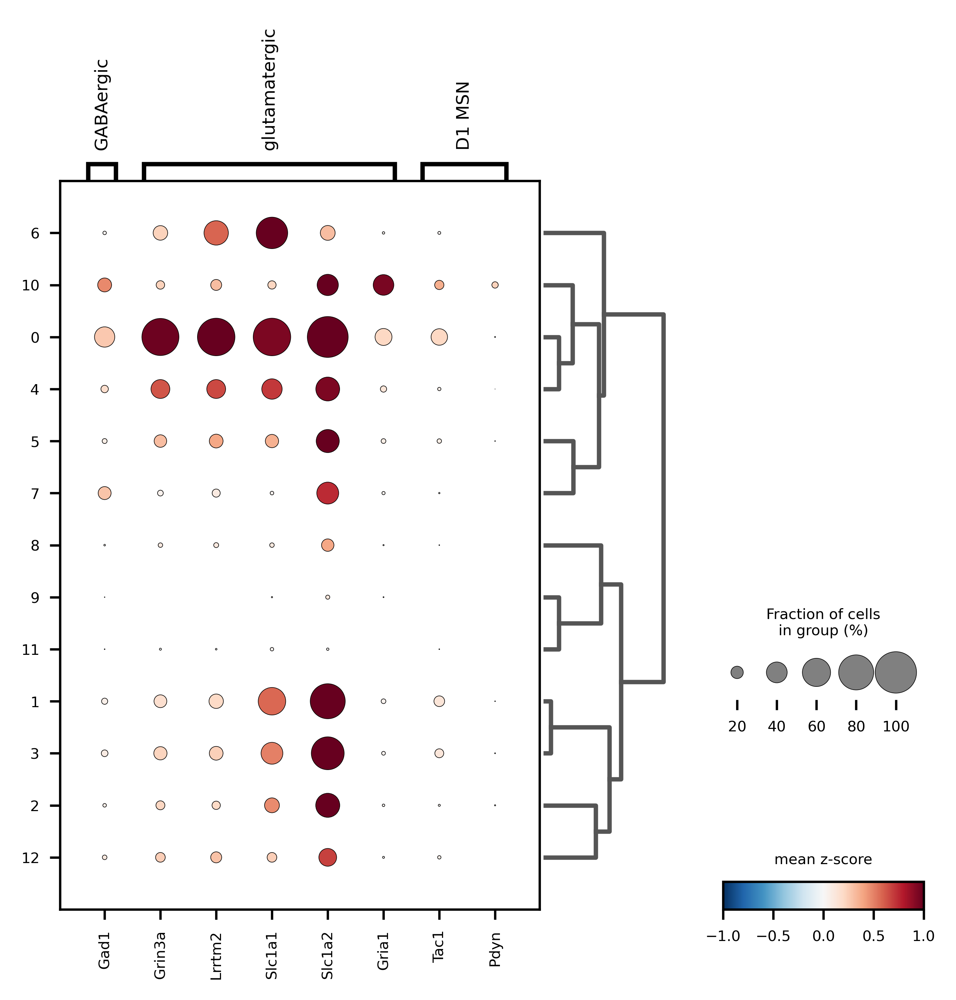

In [222]:
ax = sc.pl.dotplot(
    adata_neuron, 
    neuron_genes, 
    groupby=['leiden_neuron'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

### Label Non-Neuron

In [223]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

In [224]:
adata_non_neuron

AnnData object with n_obs × n_vars = 8608 × 10013
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels', '_scvi_local_l_mean', '_scvi_local_l_var', 'leiden_scVI', 'Snap25 label', 'TdT label', 'Sox11 label', 'label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: '_scvi', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_scVI_colors', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categoricals'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [225]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [226]:
sc.tl.pca(adata_non_neuron)

In [227]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)

In [228]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.5)

In [260]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    if int(l) in [4,5,10,12,13,14]: leiden_list.append('Microglia')
    elif int(l) in [0,2]: leiden_list.append('Endothelial')
    elif int(l) in [3,7,8,11,15]: leiden_list.append('Oligodendrocytes')
    elif int(l) in [9]: leiden_list.append('Astrocytes')
    elif int(l) in [1,6]: leiden_list.append('OPCs')
#     elif int(l) in [11]: leiden_list.append('interneuron')
#     # elif int(l) in [14]: leiden_list.append('neuroblast')
    
#     elif int(l) in [14]: leiden_list.append('X1')
#     elif int(l) in [13]: leiden_list.append('X2')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [261]:
sc.tl.dendrogram(
    adata_non_neuron,
    'label'
    # 'leiden_non_neuron'
) 

categories: Astrocytes, Endothelial, Microglia, etc.
var_group_labels: OPCs, interneuron, Endothelial, etc.


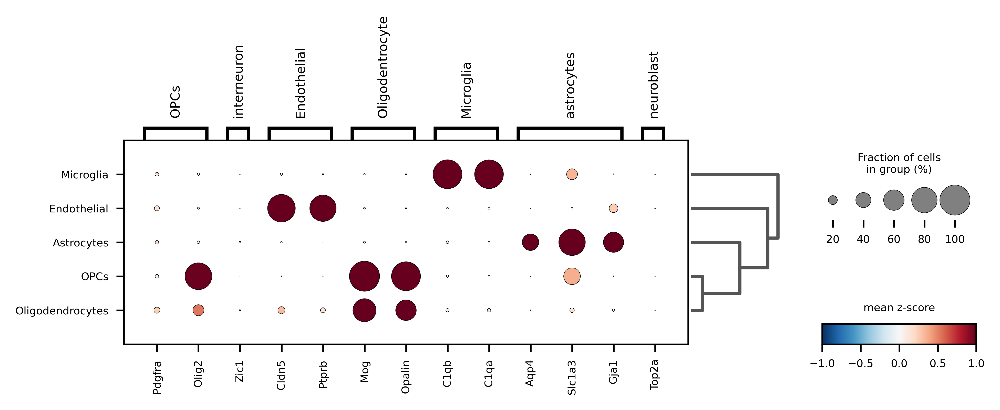

In [262]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=[
        'label'
        # 'leiden_non_neuron'
    ], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

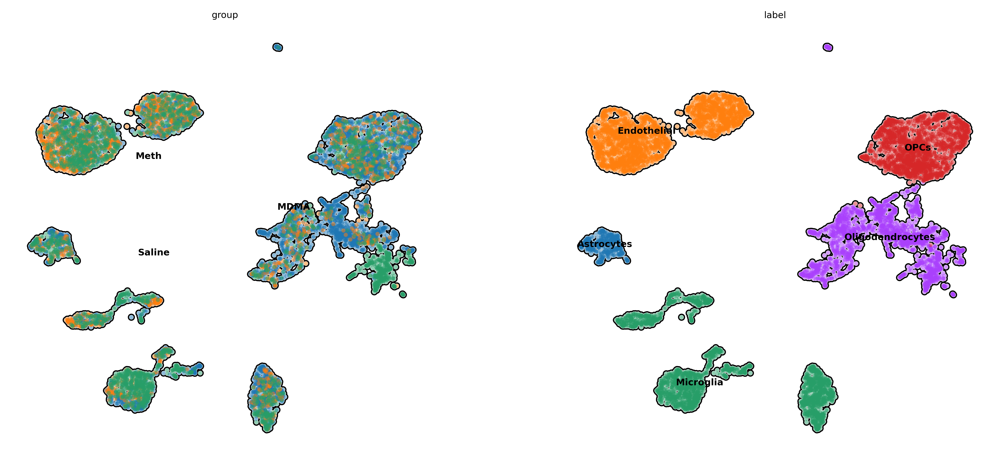

In [275]:
sc.pl.umap(
    adata_non_neuron,
    # [~adata_non_neuron.obs.leiden_scVI.isin(['2','13','15','21'])],
    color=[
        'group',
        'label'
        # 'leiden_scVI',
        # 'leiden_non_neuron',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    legend_loc='on data',
    add_outline=0.1
)

In [268]:
sc.tl.rank_genes_groups(adata_non_neuron, 'label', method='t-test')

In [273]:
non_neuron_ranks = rank_genes_to_df(adata_non_neuron, n = 50)
# non_neuron_ranks
# Snap25_pos_rankdf.to_csv('celltyping/Snap25_pos_rank_genes.csv',index=False)

# All data

In [276]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = "neuron"#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(adata.obs['final label'])

In [282]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.3)

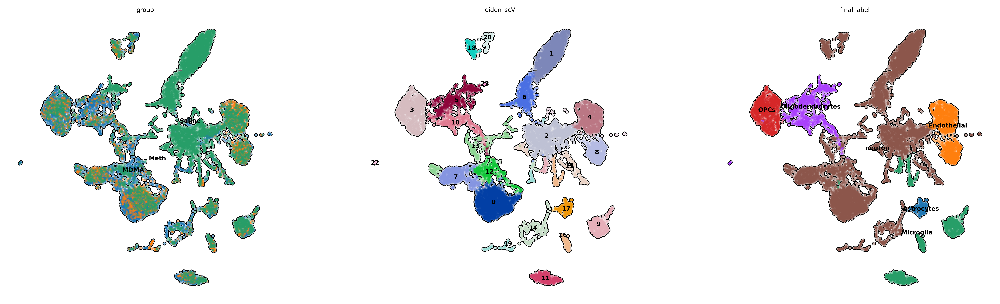

In [283]:
sc.pl.umap(
    adata,
    color=[
        'group',
        'leiden_scVI',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    legend_loc='on data',
    add_outline=0.1
)

# 

In [113]:
!date

Wed Aug 10 18:22:34 PDT 2022
